# Comparación clásico vs Qiskit — reto NTT DATA, Track A

Este notebook arma la **comparación que pide el reto para el día 1** a partir de:

- los métodos **clásicos**, que se ejecutan aquí (`qap.benchmark`, `qap.classical`);
- los resultados **cuánticos e híbridos de Diego**, que solo se leen desde `results/*.csv` (no se vuelve a correr QAOA).

**Qué exige el reto** (`reto-ntt-data/Reto_NTT_DATA.pdf`):

- Etapa 1: N=3 o N=4 (primeras N filas y columnas), óptimos de control 24 y 32; "compara **costo, factibilidad y tiempo**".
- Sección 6, comparación: "mejor costo factible, fracción factible de las muestras cuando corresponda, tiempo total y límites del método".
- "Para la instancia completa, calcula la brecha respecto del óptimo **solo sobre soluciones válidas**":
  $\text{gap}(\%) = 100\,(C - 340)/340$. Aquí `gap_pct` existe **solo para N=10**; para N<10 se usa `gap_vs_control_pct`
  (distancia al óptimo de control), que es una extensión nuestra.
- "Puedes usar el óptimo conocido para evaluar la solución, pero no como punto de partida": los métodos clásicos no lo usan;
  el óptimo solo se usa para evaluar.
- La energía penalizada del QUBO y el costo real se reportan en columnas separadas.

**Cómo regenerarlo** (rehace `results/benchmark.csv`, `results/comparison.csv` y las figuras):

```bash
uv run jupyter nbconvert --to notebook --execute --inplace notebooks/07_comparacion.ipynb
```

## 0. Configuración

In [1]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from qap.benchmark import CLASSICAL, build_benchmark, compare, write_outputs

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
FIG = ROOT / "docs" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

SURFACE, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e1"
# Okabe-Ito (colorblind-safe). Slots used: blue, vermillion, bluish green.
BLUE, VERMILLION, GREEN = "#0072B2", "#D55E00", "#009E73"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": INK2, "ytick.color": INK2, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 11.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
})
pd.set_option("display.precision", 3)
SRC = "Fuente: qap10 (MIPLIB); QAOA de results/*.csv (Aer, simulación ideal). Unidades supuestas, no mediciones."


def save(fig, name):
    """Add the source note, save to docs/figures and show the figure inline."""
    if fig.get_layout_engine() is None:
        fig.tight_layout(rect=(0, 0.04, 1, 1))
    fig.text(0.01, 0.008, SRC, fontsize=7.5, color=INK2)
    fig.savefig(FIG / name, dpi=160)
    plt.show()


def label(config: str) -> str:
    """Short Spanish label for a benchmark configuration."""
    if config == "bruteforce":
        return "fuerza bruta"
    match = re.match(r"qaoa lambda=([\d.]+)\*lambda\* reps=(\d+)", config)
    if match:
        suffix = ", normalizado" if config.endswith("normalized") else ""
        return f"QAOA λ={match.group(1)}·λ*, reps={match.group(2)}{suffix}"
    if config.startswith("local_search"):
        return "búsqueda local"
    if config.startswith("sa"):
        return "recocido simulado"
    return config.replace("hybrid_lns_exact", "LNS + subsolver exacto").replace("hybrid_lns", "LNS + QAOA")

## 1. Benchmark: clásicos ejecutados aquí + resultados de Diego

Resultados de Diego que se integran (solo lectura):

- `results/lambda_qaoa.csv` — QAOA para N=3/4 con λ ∈ {0,5; 1; 2; 4}·λ* (estudio de λ, `qap.lambda_study`).
- `results/qaoa_m5.csv` — QAOA para N=3/4 con reps ∈ {1, 2, 3} y λ = 2·λ* (`src/run_qaoa_m5.py`).
- `results/qaoa_small.csv` — QAOA **normalizado** para N=3/4 con reps ∈ {1, 2, 3} y λ = 2·λ* (`qap.hybrid_study`):
  divide el operador de costo por su mayor coeficiente para que el ángulo γ quede en una escala que COBYLA pueda explorar.
- `results/hybrid_lns.csv` — LNS híbrido para N=10, con subsolver exacto y con subsolver QAOA (`qap.hybrid_study`).

Las corridas que aparecen en dos archivos con la misma configuración y semilla se cuentan una sola vez.
La memoria pico de QAOA solo cubre las asignaciones de Python (el statevector de Aer, en C++, no se mide).

In [2]:
bench = build_benchmark(sizes=[3, 4, 10], seeds=list(range(10)), methods=list(CLASSICAL))
comparison = compare(bench)
write_outputs(bench, comparison)
print(f"{len(bench)} corridas, {len(comparison)} configuraciones; métodos clásicos: {', '.join(CLASSICAL)}")
display(bench.groupby(["n", "method", "source"]).size().rename("corridas").to_frame())

[classical] n=3 bruteforce seed=0: cost=24 (0.00s)
[classical] n=3 local_search restarts=100 seed=0: cost=24 (0.04s)
[classical] n=3 local_search restarts=100 seed=1: cost=24 (0.02s)
[classical] n=3 local_search restarts=100 seed=2: cost=24 (0.02s)
[classical] n=3 local_search restarts=100 seed=3: cost=24 (0.02s)
[classical] n=3 local_search restarts=100 seed=4: cost=24 (0.03s)
[classical] n=3 local_search restarts=100 seed=5: cost=24 (0.04s)


[classical] n=3 local_search restarts=100 seed=6: cost=24 (0.03s)
[classical] n=3 local_search restarts=100 seed=7: cost=24 (0.04s)
[classical] n=3 local_search restarts=100 seed=8: cost=24 (0.03s)
[classical] n=3 local_search restarts=100 seed=9: cost=24 (0.03s)


[classical] n=3 sa iters=10000 restarts=10 seed=0: cost=24 (2.41s)


[classical] n=3 sa iters=10000 restarts=10 seed=1: cost=24 (2.65s)


[classical] n=3 sa iters=10000 restarts=10 seed=2: cost=24 (2.41s)


...

[classical] n=10 sa iters=10000 restarts=10 seed=7: cost=340 (2.75s)


[classical] n=10 sa iters=10000 restarts=10 seed=8: cost=340 (2.76s)


[classical] n=10 sa iters=10000 restarts=10 seed=9: cost=350 (2.75s)


162 corridas, 31 configuraciones; métodos clásicos: bruteforce, local_search, sa


corridas
n  method           source                   
3  bruteforce       qap.classical           1
   local_search     qap.classical          10
   qaoa             lambda_qaoa.csv        20
                    qaoa_m5.csv            10
                    qaoa_small.csv         15
   sa               qap.classical          10
4  bruteforce       qap.classical           1
   local_search     qap.classical          10
   qaoa             lambda_qaoa.csv        12
                    qaoa_m5.csv            12
                    qaoa_small.csv          9
   sa               qap.classical          10
10 bruteforce       qap.classical           1
   hybrid_lns       hybrid_lns.csv          6
   hybrid_lns_exact hybrid_lns.csv         15
   local_search     qap.classical          10
   sa               qap.classical          10

## 2. Tabla del día 1 (N = 3 y N = 4)

Para QAOA, la **fracción factible** combina todas las semillas de una configuración y se compara con el **piso del azar**
(elegir bitstrings uniformes: N!/2^(N²) son asignaciones válidas). El p-valor es un test binomial unilateral contra ese piso.

In [3]:
day1_cols = {
    "label": "método", "runs": "corridas", "best_cost": "mejor costo válido", "reached_optimum_rate": "llega al óptimo",
    "best_gap_vs_control_pct": "distancia al óptimo de control (%)", "feasible_fraction": "fracción factible",
    "feasible_vs_floor": "× piso del azar", "p_value_vs_floor": "p-valor vs azar", "mean_seconds": "tiempo medio (s)",
}
comparison["label"] = comparison["config"].map(label)


def p_value(v: float) -> str:
    """Binomial p-values underflow to 0 for huge effects: show them as a bound."""
    return "—" if pd.isna(v) else ("< 1e-300" if v == 0 else f"{v:.1e}")


for n in (3, 4):
    table = comparison[comparison["n"] == n][list(day1_cols)].rename(columns=day1_cols)
    display(table.style.hide(axis="index").set_caption(f"N = {n} (óptimo de control {24 if n == 3 else 32})").format({
        "llega al óptimo": "{:.0%}", "fracción factible": "{:.2e}", "× piso del azar": "{:.2f}",
        "p-valor vs azar": p_value, "tiempo medio (s)": "{:.2f}", "mejor costo válido": "{:.0f}",
        "distancia al óptimo de control (%)": "{:.1f}"}, na_rep="—"))

método,corridas,mejor costo válido,llega al óptimo,distancia al óptimo de control (%),fracción factible,× piso del azar,p-valor vs azar,tiempo medio (s)
fuerza bruta,1,24,100%,0.0,—,—,—,0.00
búsqueda local,10,24,100%,0.0,—,—,—,0.03
"QAOA λ=0.5·λ*, reps=1",5,24,100%,0.0,1.04e-02,0.89,9.6e-01,6.93
"QAOA λ=1·λ*, reps=1",5,24,100%,0.0,2.27e-02,1.94,1.5e-38,7.06
"QAOA λ=2·λ*, reps=1",5,24,100%,0.0,3.74e-02,3.19,1.6e-162,6.25
"QAOA λ=2·λ*, reps=1, normalizado",5,24,100%,0.0,5.47e-02,4.67,< 1e-300,4.13
"QAOA λ=2·λ*, reps=2",5,24,100%,0.0,2.15e-02,1.84,8.9e-32,12.33
"QAOA λ=2·λ*, reps=2, normalizado",5,24,100%,0.0,6.72e-02,5.74,< 1e-300,15.04
"QAOA λ=2·λ*, reps=3",5,24,100%,0.0,5.28e-02,4.51,< 1e-300,13.68
"QAOA λ=2·λ*, reps=3, normalizado",5,24,100%,0.0,1.57e-01,13.36,< 1e-300,14.38


método,corridas,mejor costo válido,llega al óptimo,distancia al óptimo de control (%),fracción factible,× piso del azar,p-valor vs azar,tiempo medio (s)
fuerza bruta,1,32,100%,0.0,—,—,—,0.00
búsqueda local,10,32,100%,0.0,—,—,—,0.05
"QAOA λ=0.5·λ*, reps=1",3,42,0%,31.2,1.63e-04,0.44,9.4e-01,25.47
"QAOA λ=1·λ*, reps=1",3,32,67%,0.0,7.32e-04,2.00,4.0e-02,24.18
"QAOA λ=2·λ*, reps=1",5,42,0%,31.2,4.39e-04,1.20,3.4e-01,20.75
"QAOA λ=2·λ*, reps=1, normalizado",5,32,100%,0.0,1.52e-02,41.60,< 1e-300,11.10
"QAOA λ=2·λ*, reps=2",5,44,0%,37.5,2.93e-04,0.80,7.6e-01,29.74
"QAOA λ=2·λ*, reps=2, normalizado",4,32,100%,0.0,2.33e-02,63.67,< 1e-300,51.27
"QAOA λ=2·λ*, reps=3",5,32,40%,0.0,4.64e-03,12.67,6.5e-69,56.01
"QAOA λ=4·λ*, reps=1",3,32,33%,0.0,4.88e-04,1.33,3.0e-01,17.99


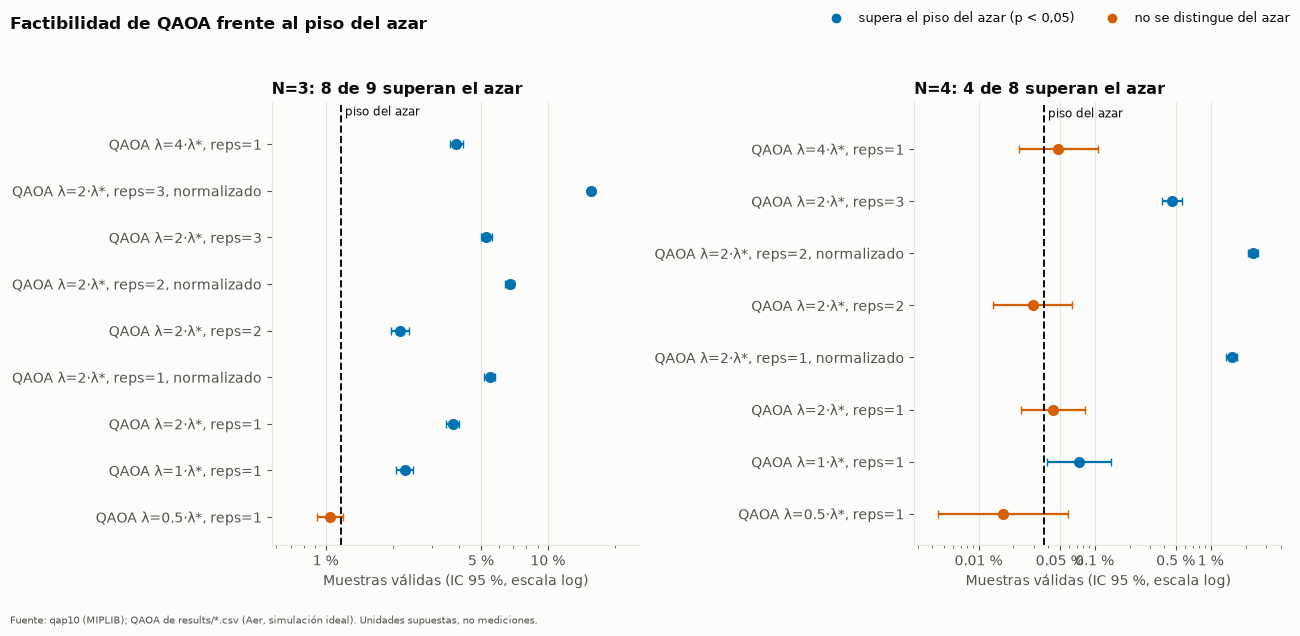

In [4]:
from matplotlib.lines import Line2D
from matplotlib.ticker import NullFormatter

NICE = np.array([1e-4, 2e-4, 5e-4, 1e-3, 2e-3, 5e-3, 1e-2, 2e-2, 5e-2, 1e-1])
qaoa = comparison[(comparison["method"] == "qaoa") & comparison["n"].isin([3, 4])].copy()
rows_max = int(qaoa.groupby("n").size().max())
fig, axes = plt.subplots(1, 2, figsize=(13, 2.2 + 0.45 * rows_max))
for ax, n in zip(axes, (3, 4)):
    sub = qaoa[qaoa["n"] == n].reset_index(drop=True)
    y = np.arange(len(sub))
    significant = sub["p_value_vs_floor"] < 0.05
    for flag, color in ((True, BLUE), (False, VERMILLION)):
        part = sub[significant == flag]
        if len(part):
            ax.errorbar(part["feasible_fraction"], part.index,
                        xerr=[part["feasible_fraction"] - part["feasible_ci_low"],
                              part["feasible_ci_high"] - part["feasible_fraction"]],
                        fmt="o", ms=7, color=color, ecolor=color, elinewidth=1.6, capsize=3)
    floor = sub["random_feasible_floor"].iat[0]
    ax.axvline(floor, color=INK, lw=1.4, ls="--")
    ax.text(floor, len(sub) - 0.45, " piso del azar", color=INK, fontsize=8.5, va="bottom")
    ax.set_xscale("log")
    low = min(sub["feasible_ci_low"].replace(0, np.nan).min(), floor) / 1.6
    high = sub["feasible_ci_high"].max() * 1.6
    ax.set_xlim(low, high)
    candidates = NICE if high / low < 30 else NICE[np.isin(NICE, [1e-4, 5e-4, 1e-3, 5e-3, 1e-2, 5e-2, 1e-1])]
    ticks = candidates[(candidates >= low) & (candidates <= high)]
    ax.set_xticks(ticks, [f"{100 * t:g} %" for t in ticks])
    ax.xaxis.set_minor_formatter(NullFormatter())
    ax.set_yticks(y, sub["label"])
    ax.set_ylim(-0.6, len(sub) - 0.1)
    ax.set_xlabel("Muestras válidas (IC 95 %, escala log)")
    ax.grid(axis="y", visible=False)
    ax.set_title(f"N={n}: {int(significant.sum())} de {len(sub)} superan el azar")
handles = [Line2D([], [], marker="o", ls="", color=BLUE, label="supera el piso del azar (p < 0,05)"),
           Line2D([], [], marker="o", ls="", color=VERMILLION, label="no se distingue del azar")]
fig.legend(handles=handles, loc="upper right", ncols=2, frameon=False, fontsize=9)
fig.suptitle("Factibilidad de QAOA frente al piso del azar", x=0.01, ha="left", fontweight="bold", fontsize=12)
fig.tight_layout(rect=(0, 0.04, 1, 0.95))
save(fig, "qaoa_vs_random_floor.png")

**Lectura.**

- **N=3:** con λ ≥ λ*, QAOA concentra varias veces más muestras válidas que el azar (diferencia muy significativa). Con
  λ = 0,5·λ* no mejora: el mínimo de energía es una asignación inválida, como predice la teoría. Llegar al óptimo en N=3
  es trivial (6 permutaciones), así que el dato informativo es la factibilidad.
- **N=4, QAOA sin normalizar:** con reps=1 o 2 y 4096 disparos no se distingue del azar (cada corrida tiene muy pocas muestras
  válidas); reps=3 sí supera el piso (~13×) y llega al óptimo en parte de las semillas.
- **N=4, QAOA normalizado (Diego):** al escalar el operador de costo, QAOA concentra **unas 40–60 veces más muestras válidas
  que el azar** y llega al óptimo (32) **en todas las semillas**. Es el resultado cuántico más sólido del proyecto.
  Es simulación ideal (Aer, sin ruido) en una instancia pequeña: no implica ventaja cuántica.

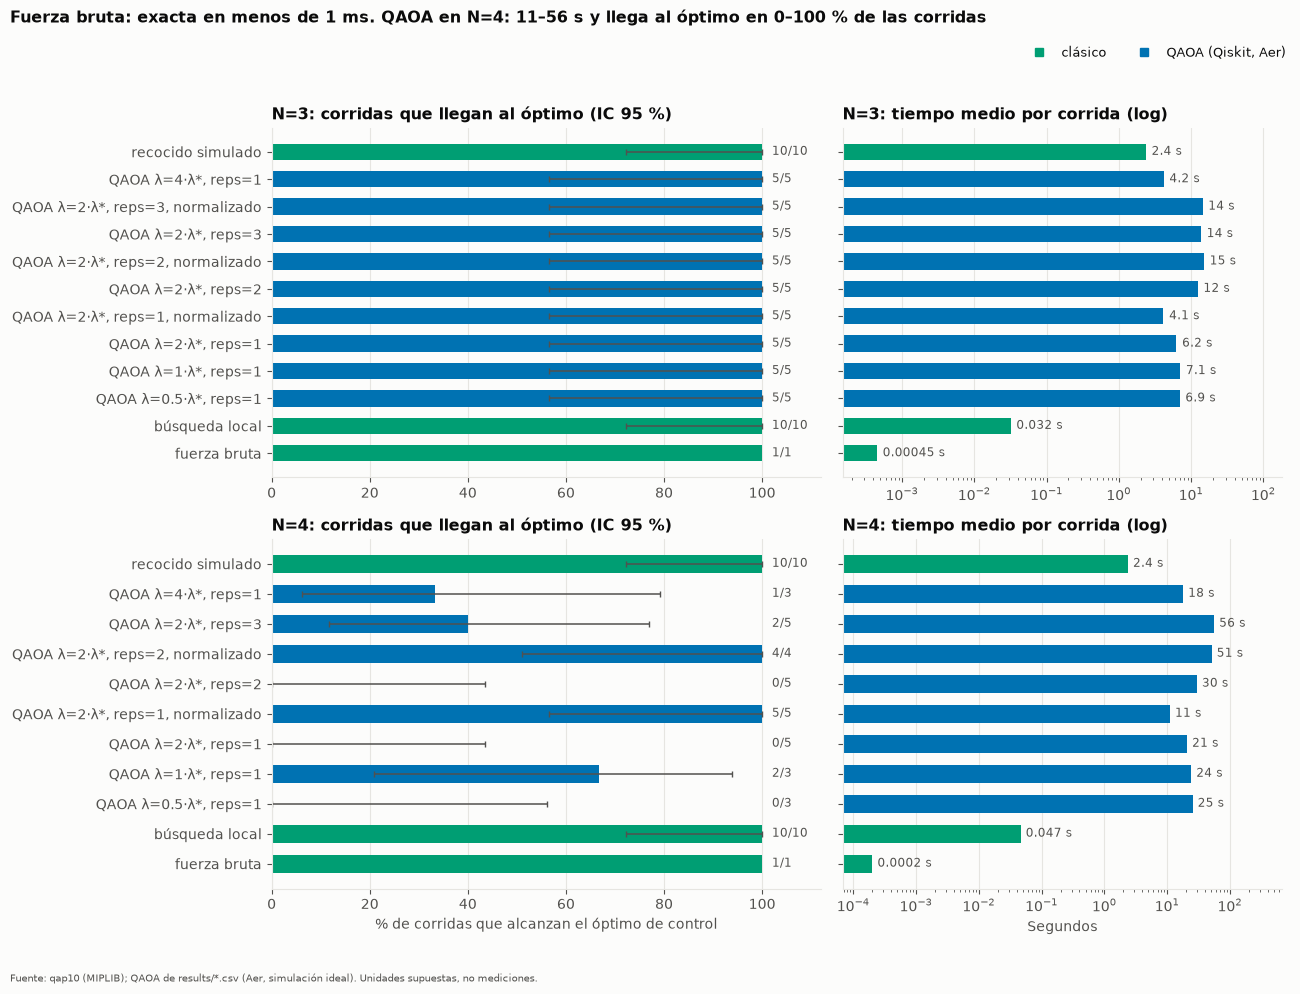

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10), gridspec_kw={"width_ratios": [1.25, 1]})
for row, n in enumerate((3, 4)):
    sub = comparison[comparison["n"] == n].reset_index(drop=True)  # every configuration, no cherry-picking
    y = np.arange(len(sub))
    colors = [GREEN if m != "qaoa" else BLUE for m in sub["method"]]
    ax = axes[row, 0]
    rate = 100 * sub["reached_optimum_rate"]
    ax.barh(y, rate, color=colors, height=0.6)
    repeated = sub["runs"] > 1  # a deterministic exact method (one run) has no sampling interval
    ax.errorbar(rate[repeated], y[repeated],
                xerr=[(rate - 100 * sub["reached_optimum_ci_low"])[repeated],
                      (100 * sub["reached_optimum_ci_high"] - rate)[repeated]],
                fmt="none", ecolor=INK2, elinewidth=1.1, capsize=2.5)
    for yi, v, k, r in zip(y, rate, sub["reached_optimum"], sub["runs"]):
        ax.text(102, yi, f"{k}/{r}", va="center", fontsize=8.5, color=INK2)
    ax.set_yticks(y, sub["label"])
    ax.set_xlim(0, 112)
    ax.grid(axis="y", visible=False)
    ax.set_title(f"N={n}: corridas que llegan al óptimo (IC 95 %)")
    ax = axes[row, 1]
    ax.barh(y, sub["mean_seconds"], color=colors, height=0.6)
    ax.set_xscale("log")
    for yi, v in zip(y, sub["mean_seconds"]):
        ax.text(v * 1.2, yi, f"{v:.2g} s", va="center", fontsize=8.5, color=INK2)
    ax.set_yticks(y, [""] * len(y))
    ax.set_xlim(sub["mean_seconds"].min() / 3, sub["mean_seconds"].max() * 12)
    ax.grid(axis="y", visible=False)
    ax.set_title(f"N={n}: tiempo medio por corrida (log)")
axes[1, 0].set_xlabel("% de corridas que alcanzan el óptimo de control")
axes[1, 1].set_xlabel("Segundos")
n4 = comparison[(comparison["n"] == 4) & (comparison["method"] == "qaoa")]
fig.suptitle(f"Fuerza bruta: exacta en menos de 1 ms. QAOA en N=4: {n4['mean_seconds'].min():.0f}–"
             f"{n4['mean_seconds'].max():.0f} s y llega al óptimo en {100 * n4['reached_optimum_rate'].min():.0f}–"
             f"{100 * n4['reached_optimum_rate'].max():.0f} % de las corridas",
             x=0.01, ha="left", fontweight="bold", fontsize=11.5)
fig.legend(handles=[Line2D([], [], marker="s", ls="", color=GREEN, label="clásico"),
                    Line2D([], [], marker="s", ls="", color=BLUE, label="QAOA (Qiskit, Aer)")],
           loc="upper right", bbox_to_anchor=(1, 0.955), ncols=2, frameon=False, fontsize=9)
fig.tight_layout(rect=(0, 0.04, 1, 0.93))
save(fig, "classical_vs_qaoa.png")

## 3. Instancia completa (N = 10): gap del reto

Aquí sí aplica la brecha del reto, $100\,(C-340)/340$, calculada solo sobre soluciones válidas. La fuerza bruta es exacta
(gap 0 %) y sirve como referencia; las filas híbridas son las corridas de Diego (LNS con subsolver exacto o QAOA).

In [6]:
n10_cols = {
    "label": "método", "runs": "corridas", "best_cost": "mejor costo", "best_gap_pct": "mejor gap del reto (%)",
    "mean_gap_pct": "gap medio (%)", "reached_optimum_rate": "llega a 340", "mean_seconds": "tiempo medio (s)",
    "max_peak_mem_mb": "memoria pico (MB)",
}
n10 = comparison[comparison["n"] == 10][list(n10_cols)].rename(columns=n10_cols)
display(n10.style.hide(axis="index").format({
    "mejor costo": "{:.0f}", "mejor gap del reto (%)": "{:.2f}", "gap medio (%)": "{:.2f}", "llega a 340": "{:.0%}",
    "tiempo medio (s)": "{:.2f}", "memoria pico (MB)": "{:.1f}"}, na_rep="—"))

método,corridas,mejor costo,mejor gap del reto (%),gap medio (%),llega a 340,tiempo medio (s),memoria pico (MB)
fuerza bruta,1,340,0.00,0.00,100%,5.25,240.1
LNS + QAOA-flow-k3,3,372,9.41,11.57,0%,126.92,2.9
LNS + QAOA-random-k3,3,366,7.65,12.75,0%,99.93,4.1
LNS + subsolver exacto-flow-k3,5,372,9.41,11.88,0%,0.23,0.4
LNS + subsolver exacto-random-k3,5,366,7.65,13.06,0%,0.24,0.4
LNS + subsolver exacto-random-k4,5,362,6.47,12.12,0%,0.32,0.5
búsqueda local,10,340,0.00,0.00,100%,0.52,0.2
recocido simulado,10,340,0.00,0.29,90%,2.77,0.5


## 4. Heurísticas clásicas

Dos heurísticas que no usan el óptimo conocido: arrancan desde permutaciones aleatorias por semilla, tienen presupuesto fijo
y no se detienen al llegar a 340.

- **Búsqueda local multiarranque:** descenso por el mejor intercambio de dos vuelos, con 100 arranques.
- **Recocido simulado:** intercambios con variación de costo exacta en O(n), temperatura inicial calibrada para aceptar
  ~80 % de subidas, enfriamiento geométrico y 10 reinicios de 10 000 iteraciones.

Son la referencia para la etapa 3 (N ≥ 14), donde la fuerza bruta deja de ser viable.

In [7]:
heur_cols = {
    "label": "método", "runs": "corridas (semillas)", "reached_optimum": "llegan al óptimo",
    "reached_optimum_rate": "tasa", "reached_optimum_ci_low": "IC 95 % bajo", "reached_optimum_ci_high": "IC 95 % alto",
    "best_gap_pct": "mejor gap del reto (%)", "mean_gap_pct": "gap medio del reto (%)", "mean_seconds": "tiempo medio (s)",
}
heur = comparison[(comparison["n"] == 10) & comparison["method"].isin(["bruteforce", "local_search", "sa"])]
display(heur[list(heur_cols)].rename(columns=heur_cols).style.hide(axis="index").set_caption("N = 10 (óptimo 340)").format({
    "tasa": "{:.0%}", "IC 95 % bajo": "{:.0%}", "IC 95 % alto": "{:.0%}", "mejor gap del reto (%)": "{:.2f}",
    "gap medio del reto (%)": "{:.2f}", "tiempo medio (s)": "{:.2f}"}, na_rep="—"))

método,corridas (semillas),llegan al óptimo,tasa,IC 95 % bajo,IC 95 % alto,mejor gap del reto (%),gap medio del reto (%),tiempo medio (s)
fuerza bruta,1,1,100%,21%,100%,0.00,0.00,5.25
búsqueda local,10,10,100%,72%,100%,0.00,0.00,0.52
recocido simulado,10,9,90%,60%,98%,0.00,0.29,2.77


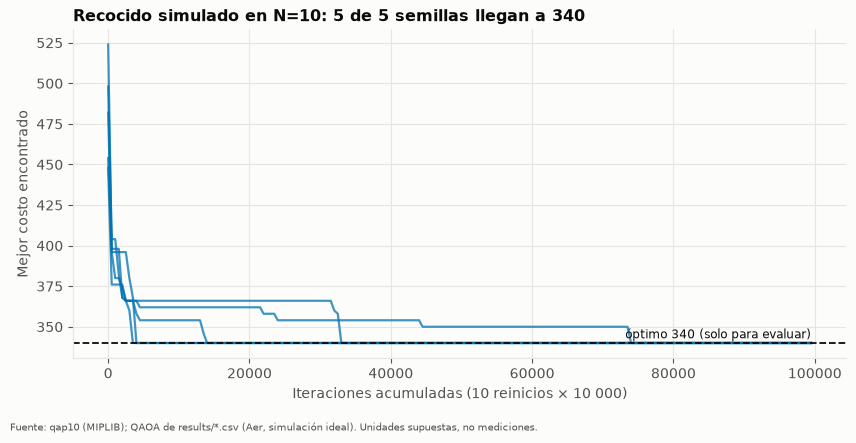

In [8]:
from qap.classical import solve_sa
from qap.data import load_instance

sa_params = CLASSICAL["sa"].params
inst10 = load_instance(10)
runs_sa = [solve_sa(inst10, seed=seed, **sa_params) for seed in range(5)]
fig, ax = plt.subplots(figsize=(8.6, 4.4))
for result in runs_sa:
    history = result.extras["history_best_cost"]
    steps = np.arange(len(history)) * result.extras["history_every"]
    ax.plot(steps, history, color=BLUE, lw=1.6, alpha=0.75)
ax.axhline(340, color=INK, lw=1.3, ls="--")
ax.text(steps[-1], 341, "óptimo 340 (solo para evaluar)", ha="right", va="bottom", fontsize=8.5)
reached = sum(r.cost == 340 for r in runs_sa)
ax.set_xlabel("Iteraciones acumuladas (10 reinicios × 10 000)")
ax.set_ylabel("Mejor costo encontrado")
ax.set_title(f"Recocido simulado en N=10: {reached} de {len(runs_sa)} semillas llegan a 340")
save(fig, "sa_convergence.png")

## 5. Conclusiones honestas

- **Línea base clásica:** la fuerza bruta resuelve N=3 y N=4 al instante y N=10 en ~5 s con el óptimo probado (340).
  Es la referencia de todas las comparaciones.
- **Heurísticas clásicas:** sin usar el óptimo, la búsqueda local multiarranque y el recocido simulado llegan a 340 en casi
  todas las semillas en N=10 en pocos segundos (ver la tabla de la sección 4). Son la vara de comparación para N ≥ 14.
- **QAOA (Qiskit, Aer):** en N=3 supera con claridad el piso del azar en factibilidad cuando λ ≥ λ*. En N=4, la versión
  **normalizada** de Diego concentra unas 40–60 veces más muestras válidas que el azar y llega al óptimo en todas las
  semillas; sin normalizar, solo reps=3 da una señal clara. No hay ventaja cuántica: lo clásico es exacto y mucho más rápido
  en estos tamaños (fuerza bruta < 1 ms, búsqueda local ~0,05 s, frente a 10–50 s de QAOA simulado).
- **Híbrido para N=10 (Diego):** el LNS con subsolver exacto o QAOA queda en un gap del reto de 6–10 % en su mejor corrida;
  las heurísticas clásicas llegan a 340. Es el punto de partida de la Fase C (día 2).
- **Gap del reto:** solo se reporta en N=10, sobre soluciones válidas. Para N=3/4 se informa la distancia al óptimo de control
  como extensión nuestra.
- **Siguiente paso recomendado para la parte cuántica:** mantener la normalización, probar λ entre 1,25 y 1,5·λ* y más
  semillas; las configuraciones sin normalizar necesitarían ≥ 22 000 disparos para ser concluyentes. Este notebook se
  actualiza solo al regenerar el benchmark.